In [4]:
import os

raw_path = '/content/drive/MyDrive/Raw Dataset'

print("Files inside Raw Dataset:\n")

for item in os.listdir(raw_path):
    print(item)

Files inside Raw Dataset:

IRD-Dataset_v1.0.0_images_Dashcam.zip
data.yaml
IRD-Dataset_v1.0.0_gps_metadata.zip
IRD-Dataset_v1.0.0_labels_bbox.zip
IRD-Dataset_v1.0.0_labels_polygon.zip
IRD-Dataset_v1.0.0_masks.zip


In [5]:
import os
import zipfile

raw_path = '/content/drive/MyDrive/Raw Dataset'

zip_files = [
    'IRD-Dataset_v1.0.0_images_Dashcam.zip',
    'IRD-Dataset_v1.0.0_labels_polygon.zip',
    'IRD-Dataset_v1.0.0_masks.zip'
]

for filename in zip_files:

    file_path = os.path.join(raw_path, filename)

    print("\n" + "="*50)
    print("FILE:", filename)

    if os.path.exists(file_path):

        with zipfile.ZipFile(file_path, 'r') as zip_ref:

            files = zip_ref.namelist()

            print("Total files:", len(files))
            print("First 15 entries:")

            for item in files[:15]:
                print(item)

    else:
        print("File not found!")


FILE: IRD-Dataset_v1.0.0_images_Dashcam.zip
Total files: 1007
First 15 entries:
images/
images/Dash_0001.jpg
images/Dash_0002.jpg
images/Dash_0003.jpg
images/Dash_0004.jpg
images/Dash_0005.jpg
images/Dash_0006.jpg
images/Dash_0007.jpg
images/Dash_0008.jpg
images/Dash_0009.jpg
images/Dash_0010.jpg
images/Dash_0011.jpg
images/Dash_0012.jpg
images/Dash_0013.jpg
images/Dash_0014.jpg

FILE: IRD-Dataset_v1.0.0_labels_polygon.zip
Total files: 4353
First 15 entries:
labels_polygon/
labels_polygon/Dash_0001.txt
labels_polygon/Dash_0002.txt
labels_polygon/Dash_0003.txt
labels_polygon/Dash_0004.txt
labels_polygon/Dash_0005.txt
labels_polygon/Dash_0006.txt
labels_polygon/Dash_0007.txt
labels_polygon/Dash_0008.txt
labels_polygon/Dash_0009.txt
labels_polygon/Dash_0010.txt
labels_polygon/Dash_0011.txt
labels_polygon/Dash_0012.txt
labels_polygon/Dash_0013.txt
labels_polygon/Dash_0014.txt

FILE: IRD-Dataset_v1.0.0_masks.zip
Total files: 7906
First 15 entries:
masks/
masks/labelmap.txt
masks/Segmentati

In [6]:
import os
import zipfile

raw_path = '/content/drive/MyDrive/Raw Dataset'

extract_path = '/content/IRD_Extracted'

os.makedirs(extract_path, exist_ok=True)

zip_files = [
    'IRD-Dataset_v1.0.0_images_Dashcam.zip',
    'IRD-Dataset_v1.0.0_labels_polygon.zip',
    'IRD-Dataset_v1.0.0_masks.zip'
]

for filename in zip_files:

    zip_path = os.path.join(raw_path, filename)

    folder_name = filename.replace('.zip', '')

    destination = os.path.join(extract_path, folder_name)

    os.makedirs(destination, exist_ok=True)

    print("Extracting:", filename)

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(destination)

    print("Completed:", folder_name)

print("\nAll three ZIP files extracted successfully!")

Extracting: IRD-Dataset_v1.0.0_images_Dashcam.zip
Completed: IRD-Dataset_v1.0.0_images_Dashcam
Extracting: IRD-Dataset_v1.0.0_labels_polygon.zip
Completed: IRD-Dataset_v1.0.0_labels_polygon
Extracting: IRD-Dataset_v1.0.0_masks.zip
Completed: IRD-Dataset_v1.0.0_masks

All three ZIP files extracted successfully!


In [7]:
import zipfile
import os

raw_path = '/content/drive/MyDrive/Raw Dataset'

# Open the mask ZIP file
mask_zip = os.path.join(
    raw_path,
    'IRD-Dataset_v1.0.0_masks.zip'
)

with zipfile.ZipFile(mask_zip, 'r') as z:

    labelmap_file = 'masks/labelmap.txt'

    print("ORIGINAL DATASET CLASS INFORMATION\n")

    if labelmap_file in z.namelist():

        content = z.read(labelmap_file).decode('utf-8')

        print(content)

    else:
        print("Labelmap file not found!")

ORIGINAL DATASET CLASS INFORMATION

# label:color_rgb:parts:actions
D00_LongitudinalCrack:50,183,250::
D10_TransverseCrack:255,204,51::
D20_AlligatorCrack:240,120,240::
D40_Pothole:9,5,29::
SpeedBump:102,255,102::
background:0,0,0::



In [8]:
import zipfile
import os

raw_path = '/content/drive/MyDrive/Raw Dataset'

polygon_zip = os.path.join(
    raw_path,
    'IRD-Dataset_v1.0.0_labels_polygon.zip'
)

with zipfile.ZipFile(polygon_zip, 'r') as z:

    # Read one Dashcam annotation
    file_name = 'labels_polygon/Dash_0001.txt'

    content = z.read(file_name).decode('utf-8')

    print("Sample Dashcam Polygon Annotation:")
    print("----------------------------------")
    print(content)

Sample Dashcam Polygon Annotation:
----------------------------------
3 0.384401 0.294954 0.420599 0.298009 0.442635 0.305028 0.433591 0.318093 0.399115 0.317130 0.368021 0.313056



In [9]:
import zipfile
import os

raw_path = '/content/drive/MyDrive/Raw Dataset'

polygon_zip = os.path.join(
    raw_path,
    'IRD-Dataset_v1.0.0_labels_polygon.zip'
)

pothole_class_id = 3

pothole_images = []
non_pothole_images = []
empty_labels = []

with zipfile.ZipFile(polygon_zip, 'r') as z:

    for filename in z.namelist():

        if not filename.startswith('labels_polygon/Dash_'):
            continue

        if not filename.endswith('.txt'):
            continue

        content = z.read(filename).decode('utf-8').strip()

        image_name = os.path.basename(filename).replace('.txt', '.jpg')

        if not content:
            empty_labels.append(image_name)
            continue

        contains_pothole = False

        for line in content.splitlines():

            values = line.split()

            if values and values[0] == str(pothole_class_id):
                contains_pothole = True
                break

        if contains_pothole:
            pothole_images.append(image_name)
        else:
            non_pothole_images.append(image_name)

print("DASHCAM POTHOLE ANALYSIS")
print("-" * 40)

print("Images with potholes:", len(pothole_images))
print("Images without potholes:", len(non_pothole_images))
print("Empty annotation files:", len(empty_labels))

print("\nFirst 10 pothole images:")

for image in pothole_images[:10]:
    print(image)

DASHCAM POTHOLE ANALYSIS
----------------------------------------
Images with potholes: 132
Images without potholes: 672
Empty annotation files: 202

First 10 pothole images:
Dash_0001.jpg
Dash_0002.jpg
Dash_0003.jpg
Dash_0014.jpg
Dash_0039.jpg
Dash_0061.jpg
Dash_0068.jpg
Dash_0073.jpg
Dash_0074.jpg
Dash_0075.jpg


In [10]:
import zipfile
import os

raw_path = '/content/drive/MyDrive/Raw Dataset'

image_zip = os.path.join(
    raw_path,
    'IRD-Dataset_v1.0.0_images_Dashcam.zip'
)

polygon_zip = os.path.join(
    raw_path,
    'IRD-Dataset_v1.0.0_labels_polygon.zip'
)

available_images = set()
available_labels = set()

# Read image filenames
with zipfile.ZipFile(image_zip, 'r') as z:
    for name in z.namelist():
        if name.startswith('images/Dash_') and name.lower().endswith(('.jpg', '.jpeg', '.png')):
            available_images.add(os.path.basename(name))

# Read polygon filenames
with zipfile.ZipFile(polygon_zip, 'r') as z:
    for name in z.namelist():
        if name.startswith('labels_polygon/Dash_') and name.endswith('.txt'):
            available_labels.add(os.path.basename(name).replace('.txt', '.jpg'))

# Check matching files
matching = available_images.intersection(pothole_images)

missing_images = set(pothole_images) - available_images

print("POTHOLE IMAGE VERIFICATION")
print("-" * 40)

print("Total pothole images identified:", len(pothole_images))
print("Images available in image ZIP:", len(matching))
print("Missing images:", len(missing_images))

if missing_images:
    print("\nMissing image filenames:")
    print(missing_images)

print("\nVerification completed.")

POTHOLE IMAGE VERIFICATION
----------------------------------------
Total pothole images identified: 132
Images available in image ZIP: 132
Missing images: 0

Verification completed.


In [11]:
import os

processed_path = '/content/Prepared_Dataset'

os.makedirs(processed_path + '/images', exist_ok=True)
os.makedirs(processed_path + '/labels', exist_ok=True)

print("Processed dataset folders created!")

print(os.listdir(processed_path))

Processed dataset folders created!
['labels', 'images']


In [12]:
import zipfile
import os

raw_path = '/content/drive/MyDrive/Raw Dataset'

image_zip = os.path.join(
    raw_path,
    'IRD-Dataset_v1.0.0_images_Dashcam.zip'
)

polygon_zip = os.path.join(
    raw_path,
    'IRD-Dataset_v1.0.0_labels_polygon.zip'
)

processed_path = '/content/Prepared_Dataset'

image_output = os.path.join(processed_path, 'images')
label_output = os.path.join(processed_path, 'labels')

pothole_class_id = 3

processed_count = 0
invalid_labels = []
missing_images = []

# Read original Dashcam images
with zipfile.ZipFile(image_zip, 'r') as img_zip:

    image_files = {}

    for name in img_zip.namelist():

        if name.startswith('images/Dash_') and name.lower().endswith(('.jpg', '.jpeg', '.png')):

            image_files[os.path.basename(name)] = name

    # Read original polygon annotations
    with zipfile.ZipFile(polygon_zip, 'r') as label_zip:

        for name in label_zip.namelist():

            if not name.startswith('labels_polygon/Dash_') or not name.endswith('.txt'):
                continue

            content = label_zip.read(name).decode('utf-8').strip()

            if not content:
                continue

            pothole_annotations = []

            for line in content.splitlines():

                values = line.split()

                if not values:
                    continue

                if values[0] == str(pothole_class_id):

                    # Convert original class ID 3 to final ID 0
                    values[0] = '0'

                    # Validate polygon coordinates
                    try:
                        coordinates = [float(x) for x in values[1:]]

                        if len(coordinates) < 6 or len(coordinates) % 2 != 0:
                            invalid_labels.append(name)
                            continue

                        pothole_annotations.append(
                            ' '.join(values)
                        )

                    except ValueError:
                        invalid_labels.append(name)

            if not pothole_annotations:
                continue

            image_name = os.path.basename(name).replace('.txt', '.jpg')

            if image_name not in image_files:
                missing_images.append(image_name)
                continue

            # Extract original image
            img_zip.extract(
                image_files[image_name],
                '/content/temp_ird'
            )

            source_image = os.path.join(
                '/content/temp_ird',
                image_files[image_name]
            )

            import shutil

            shutil.copy2(
                source_image,
                os.path.join(image_output, image_name)
            )

            # Save only pothole annotations
            label_name = os.path.basename(name)

            with open(
                os.path.join(label_output, label_name),
                'w'
            ) as f:

                f.write('\n'.join(pothole_annotations))

            processed_count += 1

print("\nDATASET EXTRACTION SUMMARY")
print("-" * 40)

print("Processed pothole images:", processed_count)
print("Invalid annotations:", len(invalid_labels))
print("Missing images:", len(missing_images))


DATASET EXTRACTION SUMMARY
----------------------------------------
Processed pothole images: 132
Invalid annotations: 0
Missing images: 0


In [13]:
import os
from PIL import Image

image_path = '/content/Prepared_Dataset/images'

total_images = 0
valid_images = 0
corrupted_images = []
image_formats = {}
image_dimensions = {}

for filename in os.listdir(image_path):

    filepath = os.path.join(image_path, filename)

    if not filename.lower().endswith(('.jpg', '.jpeg', '.png')):
        continue

    total_images += 1

    try:
        with Image.open(filepath) as img:

            img.verify()

        with Image.open(filepath) as img:

            valid_images += 1

            image_format = img.format
            dimensions = img.size

            image_formats[image_format] = image_formats.get(image_format, 0) + 1

            image_dimensions[dimensions] = image_dimensions.get(dimensions, 0) + 1

    except Exception:
        corrupted_images.append(filename)

print("IMAGE QUALITY VERIFICATION")
print("-" * 40)

print("Total images:", total_images)
print("Readable images:", valid_images)
print("Corrupted images:", len(corrupted_images))

print("\nImage formats:")
for fmt, count in image_formats.items():
    print(fmt, ":", count)

print("\nImage dimensions:")
for dimension, count in image_dimensions.items():
    print(dimension, ":", count)

if corrupted_images:
    print("\nCorrupted image filenames:")
    print(corrupted_images)

IMAGE QUALITY VERIFICATION
----------------------------------------
Total images: 132
Readable images: 132
Corrupted images: 0

Image formats:
JPEG : 132

Image dimensions:
(3840, 2160) : 132


In [14]:
import os
import hashlib
from collections import defaultdict

image_path = '/content/Prepared_Dataset/images'

image_hashes = defaultdict(list)

for filename in os.listdir(image_path):

    filepath = os.path.join(image_path, filename)

    if not filename.lower().endswith(('.jpg', '.jpeg', '.png')):
        continue

    with open(filepath, 'rb') as f:
        file_hash = hashlib.sha256(f.read()).hexdigest()

    image_hashes[file_hash].append(filename)

duplicates = []

for files in image_hashes.values():

    if len(files) > 1:
        duplicates.append(files)

total_images = sum(len(files) for files in image_hashes.values())
unique_images = len(image_hashes)

print("DUPLICATE IMAGE VERIFICATION")
print("-" * 40)

print("Total images:", total_images)
print("Unique images:", unique_images)
print("Duplicate groups:", len(duplicates))

if duplicates:

    print("\nDuplicate image files:")

    for group in duplicates:
        print(group)

else:
    print("\nNo duplicate images found.")

DUPLICATE IMAGE VERIFICATION
----------------------------------------
Total images: 132
Unique images: 131
Duplicate groups: 1

Duplicate image files:
['Dash_0930.jpg', 'Dash_0633.jpg']


In [15]:
import os

image_path = '/content/Prepared_Dataset/images'
label_path = '/content/Prepared_Dataset/labels'

duplicate_image = 'Dash_0930.jpg'
duplicate_label = 'Dash_0930.txt'

# Remove duplicate image
image_file = os.path.join(image_path, duplicate_image)

if os.path.exists(image_file):
    os.remove(image_file)
    print("Duplicate image removed:", duplicate_image)

# Remove corresponding annotation
label_file = os.path.join(label_path, duplicate_label)

if os.path.exists(label_file):
    os.remove(label_file)
    print("Corresponding annotation removed:", duplicate_label)

print("\nDuplicate removal completed.")

Duplicate image removed: Dash_0930.jpg
Corresponding annotation removed: Dash_0930.txt

Duplicate removal completed.


In [16]:
import os

image_path = '/content/Prepared_Dataset/images'
label_path = '/content/Prepared_Dataset/labels'

image_files = {
    os.path.splitext(f)[0]
    for f in os.listdir(image_path)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
}

label_files = {
    os.path.splitext(f)[0]
    for f in os.listdir(label_path)
    if f.lower().endswith('.txt')
}

missing_labels = image_files - label_files
missing_images = label_files - image_files

empty_labels = []

for filename in os.listdir(label_path):

    if filename.endswith('.txt'):

        filepath = os.path.join(label_path, filename)

        if os.path.getsize(filepath) == 0:
            empty_labels.append(filename)

print("IMAGE AND ANNOTATION VERIFICATION")
print("-" * 45)

print("Total images:", len(image_files))
print("Total annotations:", len(label_files))

print("Images without annotations:", len(missing_labels))
print("Annotations without images:", len(missing_images))
print("Empty annotations:", len(empty_labels))

if missing_labels:
    print("\nMissing labels:", missing_labels)

if missing_images:
    print("\nMissing images:", missing_images)

if empty_labels:
    print("\nEmpty labels:", empty_labels)

IMAGE AND ANNOTATION VERIFICATION
---------------------------------------------
Total images: 131
Total annotations: 131
Images without annotations: 0
Annotations without images: 0
Empty annotations: 0


In [17]:
import os

label_path = '/content/Prepared_Dataset/labels'

total_labels = 0
valid_labels = 0
invalid_labels = []

for filename in os.listdir(label_path):

    if not filename.endswith('.txt'):
        continue

    total_labels += 1

    filepath = os.path.join(label_path, filename)

    try:
        with open(filepath, 'r') as f:
            lines = f.readlines()

        for line_number, line in enumerate(lines, start=1):

            values = line.strip().split()

            if len(values) < 7:
                raise ValueError("Insufficient polygon coordinates")

            if values[0] != '0':
                raise ValueError("Incorrect class ID")

            coordinates = [float(x) for x in values[1:]]

            if len(coordinates) % 2 != 0:
                raise ValueError("Odd number of coordinates")

            if any(x < 0 or x > 1 for x in coordinates):
                raise ValueError("Coordinates outside 0-1 range")

        valid_labels += 1

    except Exception as e:
        invalid_labels.append((filename, str(e)))

print("POLYGON ANNOTATION VERIFICATION")
print("-" * 45)

print("Total annotation files:", total_labels)
print("Valid annotation files:", valid_labels)
print("Invalid annotation files:", len(invalid_labels))

if invalid_labels:
    print("\nInvalid annotations:")
    for item in invalid_labels:
        print(item)

POLYGON ANNOTATION VERIFICATION
---------------------------------------------
Total annotation files: 131
Valid annotation files: 131
Invalid annotation files: 0


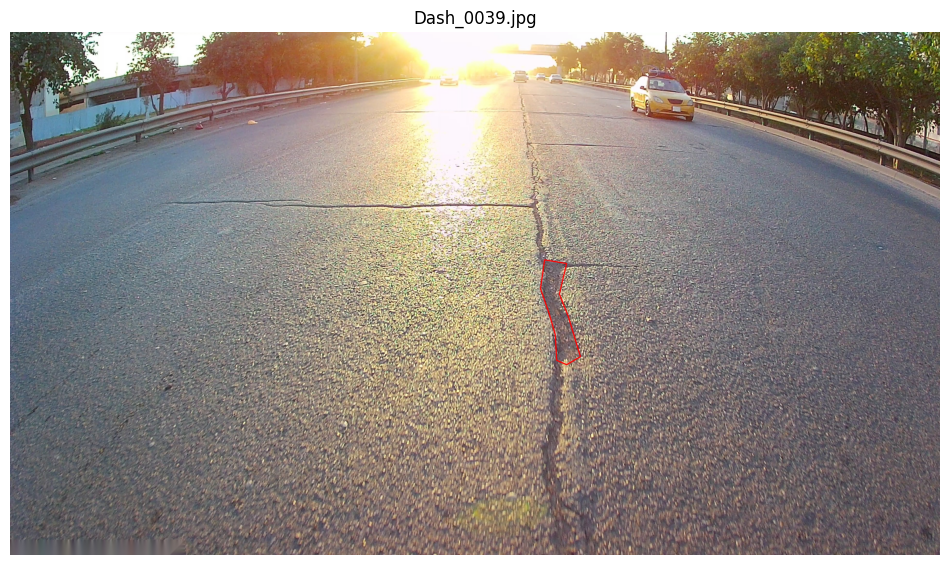

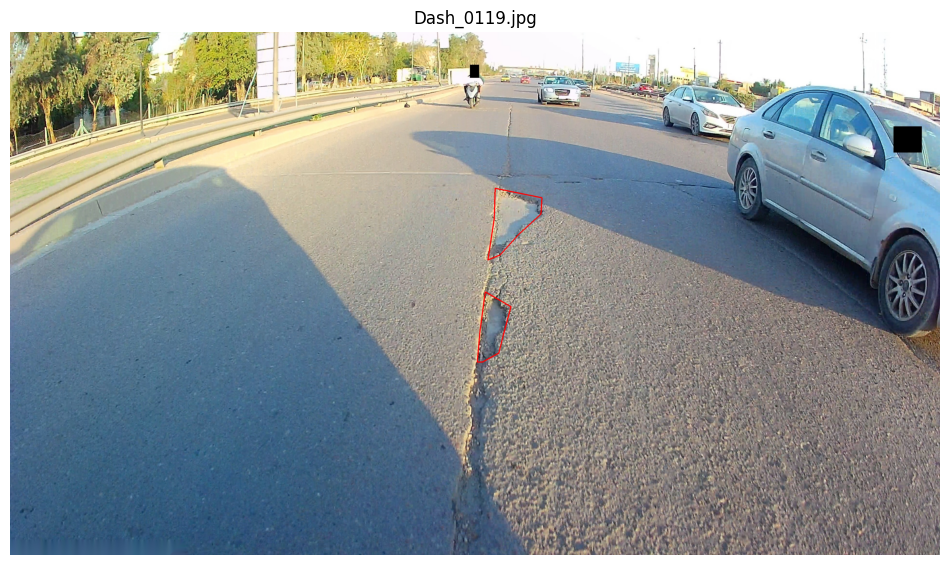

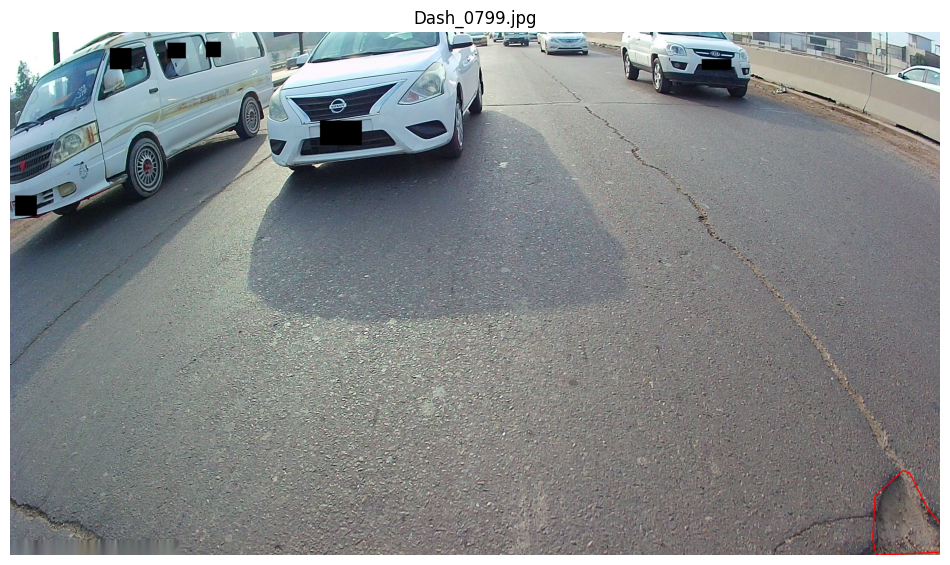

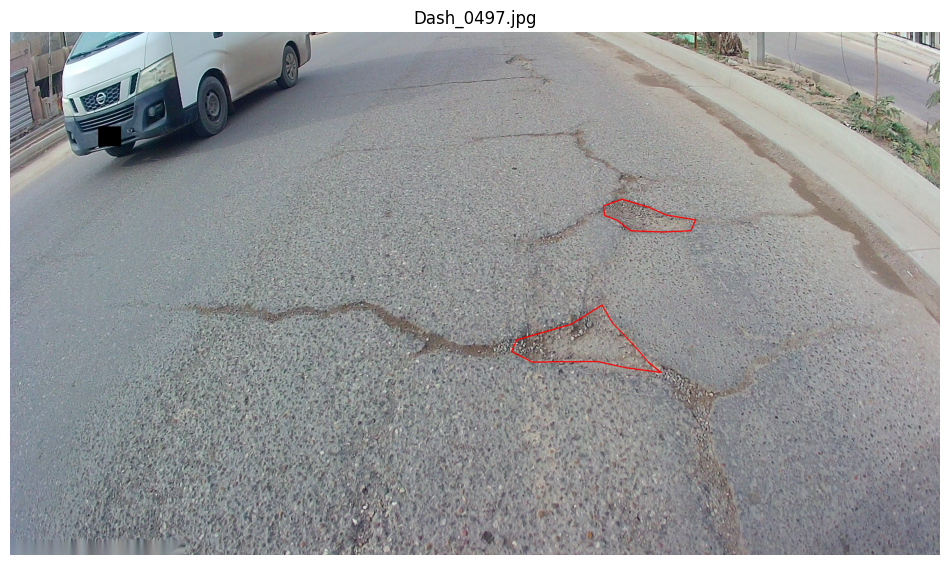

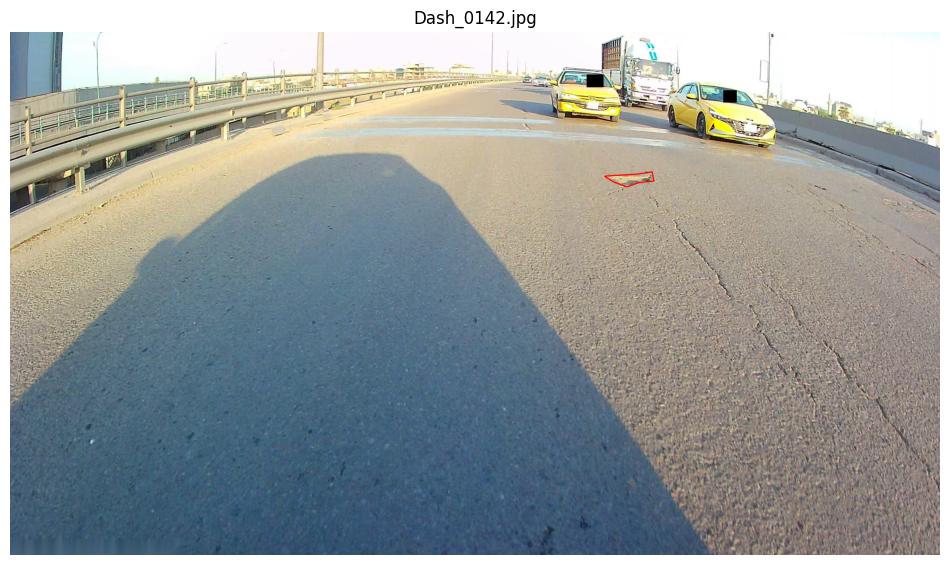

In [18]:
import os
import random
import cv2
import matplotlib.pyplot as plt

image_path = '/content/Prepared_Dataset/images'
label_path = '/content/Prepared_Dataset/labels'

image_files = [
    f for f in os.listdir(image_path)
    if f.lower().endswith('.jpg')
]

sample_images = random.sample(image_files, min(5, len(image_files)))

for filename in sample_images:

    img = cv2.imread(os.path.join(image_path, filename))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    label_file = os.path.join(
        label_path,
        os.path.splitext(filename)[0] + '.txt'
    )

    with open(label_file, 'r') as f:

        for line in f:

            values = line.strip().split()

            coordinates = list(map(float, values[1:]))

            points = []

            for i in range(0, len(coordinates), 2):

                x = int(coordinates[i] * img.shape[1])
                y = int(coordinates[i + 1] * img.shape[0])

                points.append([x, y])

            points = __import__('numpy').array(
                points, dtype='int32'
            )

            cv2.polylines(
                img,
                [points],
                True,
                (255, 0, 0),
                4
            )

    plt.figure(figsize=(12, 7))
    plt.imshow(img)
    plt.title(filename)
    plt.axis('off')
    plt.show()

In [19]:
import os

label_path = '/content/Prepared_Dataset/labels'

class_ids = set()
total_polygons = 0
incorrect_classes = []

for filename in os.listdir(label_path):

    if not filename.endswith('.txt'):
        continue

    filepath = os.path.join(label_path, filename)

    with open(filepath, 'r') as f:

        for line in f:

            values = line.strip().split()

            if values:
                class_id = values[0]
                class_ids.add(class_id)
                total_polygons += 1

                if class_id != '0':
                    incorrect_classes.append(filename)

print("CLASS ID VERIFICATION")
print("-" * 40)

print("Total polygons:", total_polygons)
print("Class IDs found:", class_ids)
print("Incorrect class annotations:", len(incorrect_classes))

CLASS ID VERIFICATION
----------------------------------------
Total polygons: 173
Class IDs found: {'0'}
Incorrect class annotations: 0


In [20]:
import os

label_path = '/content/Prepared_Dataset/labels'

total_polygons = 0
valid_polygons = 0
invalid_polygons = []

for filename in os.listdir(label_path):

    if not filename.endswith('.txt'):
        continue

    filepath = os.path.join(label_path, filename)

    with open(filepath, 'r') as f:

        for line_number, line in enumerate(f, start=1):

            values = line.strip().split()

            total_polygons += 1

            try:

                class_id = int(values[0])
                coordinates = [float(x) for x in values[1:]]

                if class_id != 0:
                    raise ValueError("Incorrect class ID")

                if len(coordinates) < 6:
                    raise ValueError("Less than 3 polygon points")

                if len(coordinates) % 2 != 0:
                    raise ValueError("Odd number of coordinates")

                if not all(0 <= x <= 1 for x in coordinates):
                    raise ValueError("Coordinates outside normalized range")

                valid_polygons += 1

            except Exception as e:

                invalid_polygons.append(
                    (filename, line_number, str(e))
                )

print("ANNOTATION FORMAT VERIFICATION")
print("-" * 45)

print("Total polygons:", total_polygons)
print("Valid polygons:", valid_polygons)
print("Invalid polygons:", len(invalid_polygons))

if invalid_polygons:
    print("\nInvalid annotations:")
    for item in invalid_polygons:
        print(item)

ANNOTATION FORMAT VERIFICATION
---------------------------------------------
Total polygons: 173
Valid polygons: 173
Invalid polygons: 0


In [21]:
import os

base_path = '/content/Prepared_Dataset'

folders = [
    'images/train',
    'images/val',
    'images/test',
    'labels/train',
    'labels/val',
    'labels/test'
]

for folder in folders:

    path = os.path.join(base_path, folder)

    os.makedirs(path, exist_ok=True)

print("YOLOv8 segmentation folders created!")

for folder in folders:
    print(folder)

YOLOv8 segmentation folders created!
images/train
images/val
images/test
labels/train
labels/val
labels/test


In [22]:
import os
import random
import shutil

base_path = '/content/Prepared_Dataset'

image_source = os.path.join(base_path, 'images')
label_source = os.path.join(base_path, 'labels')

image_files = [
    f for f in os.listdir(image_source)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

# Shuffle images reproducibly
random.seed(42)
random.shuffle(image_files)

total = len(image_files)

train_count = int(total * 0.70)
val_count = int(total * 0.20)

train_files = image_files[:train_count]
val_files = image_files[train_count:train_count + val_count]
test_files = image_files[train_count + val_count:]

splits = {
    'train': train_files,
    'val': val_files,
    'test': test_files
}

for split, files in splits.items():

    for image_name in files:

        image_name_without_extension = os.path.splitext(image_name)[0]

        label_name = image_name_without_extension + '.txt'

        source_image = os.path.join(image_source, image_name)
        source_label = os.path.join(label_source, label_name)

        destination_image = os.path.join(
            image_source, split, image_name
        )

        destination_label = os.path.join(
            label_source, split, label_name
        )

        shutil.copy2(source_image, destination_image)
        shutil.copy2(source_label, destination_label)

print("DATASET SPLITTING SUMMARY")
print("-" * 40)

for split, files in splits.items():
    print(f"{split.upper()}: {len(files)} images")

print("\nTotal images distributed:", sum(len(v) for v in splits.values()))

DATASET SPLITTING SUMMARY
----------------------------------------
TRAIN: 91 images
VAL: 26 images
TEST: 14 images

Total images distributed: 131


In [23]:
import os

base_path = '/content/Prepared_Dataset'

splits = ['train', 'val', 'test']

print("DATASET SPLIT VERIFICATION")
print("-" * 45)

for split in splits:

    image_dir = os.path.join(base_path, 'images', split)
    label_dir = os.path.join(base_path, 'labels', split)

    images = {
        os.path.splitext(f)[0]
        for f in os.listdir(image_dir)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    }

    labels = {
        os.path.splitext(f)[0]
        for f in os.listdir(label_dir)
        if f.endswith('.txt')
    }

    missing_labels = images - labels
    missing_images = labels - images

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Missing labels:", len(missing_labels))
    print("Missing images:", len(missing_images))

print("\nVerification completed.")

DATASET SPLIT VERIFICATION
---------------------------------------------

TRAIN
Images: 91
Labels: 91
Missing labels: 0
Missing images: 0

VAL
Images: 26
Labels: 26
Missing labels: 0
Missing images: 0

TEST
Images: 14
Labels: 14
Missing labels: 0
Missing images: 0

Verification completed.


In [24]:
import yaml
import os

base_path = '/content/Prepared_Dataset'

data = {
    'path': base_path,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'nc': 1,
    'names': ['pothole']
}

yaml_path = os.path.join(base_path, 'data.yaml')

with open(yaml_path, 'w') as file:
    yaml.dump(data, file, sort_keys=False)

print("data.yaml created successfully!")

with open(yaml_path, 'r') as file:
    print("\nDATA.YAML CONTENT:\n")
    print(file.read())

data.yaml created successfully!

DATA.YAML CONTENT:

path: /content/Prepared_Dataset
train: images/train
val: images/val
test: images/test
nc: 1
names:
- pothole



In [25]:
import os
import csv
from PIL import Image

base_path = '/content/Prepared_Dataset'

splits = ['train', 'val', 'test']

statistics = []

for split in splits:

    image_dir = os.path.join(base_path, 'images', split)
    label_dir = os.path.join(base_path, 'labels', split)

    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    labels = [
        f for f in os.listdir(label_dir)
        if f.endswith('.txt')
    ]

    total_polygons = 0

    for filename in labels:

        with open(os.path.join(label_dir, filename), 'r') as f:
            total_polygons += sum(1 for line in f if line.strip())

    statistics.append({
        'Dataset': split,
        'Total_Images': len(images),
        'Total_Annotations': len(labels),
        'Total_Pothole_Polygons': total_polygons
    })

# Overall statistics
total_images = sum(row['Total_Images'] for row in statistics)
total_annotations = sum(row['Total_Annotations'] for row in statistics)
total_polygons = sum(row['Total_Pothole_Polygons'] for row in statistics)

statistics.append({
    'Dataset': 'Total',
    'Total_Images': total_images,
    'Total_Annotations': total_annotations,
    'Total_Pothole_Polygons': total_polygons
})

csv_path = os.path.join(base_path, 'dataset_statistics.csv')

with open(csv_path, 'w', newline='') as file:

    writer = csv.DictWriter(
        file,
        fieldnames=[
            'Dataset',
            'Total_Images',
            'Total_Annotations',
            'Total_Pothole_Polygons'
        ]
    )

    writer.writeheader()
    writer.writerows(statistics)

print("Dataset statistics CSV created successfully!")

for row in statistics:
    print(row)

Dataset statistics CSV created successfully!
{'Dataset': 'train', 'Total_Images': 91, 'Total_Annotations': 91, 'Total_Pothole_Polygons': 121}
{'Dataset': 'val', 'Total_Images': 26, 'Total_Annotations': 26, 'Total_Pothole_Polygons': 37}
{'Dataset': 'test', 'Total_Images': 14, 'Total_Annotations': 14, 'Total_Pothole_Polygons': 15}
{'Dataset': 'Total', 'Total_Images': 131, 'Total_Annotations': 131, 'Total_Pothole_Polygons': 173}


In [26]:
import os

base_path = '/content/Prepared_Dataset'

folders = [
    'images/train',
    'images/val',
    'images/test',
    'labels/train',
    'labels/val',
    'labels/test'
]

print("FINAL DATASET STRUCTURE")
print("=" * 45)

for folder in folders:

    path = os.path.join(base_path, folder)

    files = os.listdir(path)

    print(f"{folder}: {len(files)} files")

print("\nRequired configuration files:")

for filename in ['data.yaml', 'dataset_statistics.csv']:

    path = os.path.join(base_path, filename)

    print(filename, ":", "Available" if os.path.exists(path) else "Missing")


FINAL DATASET STRUCTURE
images/train: 91 files
images/val: 26 files
images/test: 14 files
labels/train: 91 files
labels/val: 26 files
labels/test: 14 files

Required configuration files:
data.yaml : Available
dataset_statistics.csv : Available


In [27]:
import os

mydrive = '/content/drive/MyDrive'

print("Folders in My Drive:\n")

for item in os.listdir(mydrive):
    print(item)

Folders in My Drive:

Classroom
IMG_20240517_214823.jpg
IMG_20240517_214841.jpg
IMG_20240824_200502.jpg
IMG_20240824_200528.jpg
madhu photo .pdf
1000010148.jpg
ex1.gdoc
1000036735.jpg
inbound3322535649764299284.jpg
inbound7117598480483822452.pdf
Resume (1).pdf
Colab Notebooks
1000054600.jpg
Screenshot_20250428_091431.jpg
Screenshot_20250428_091511.jpg
1035_MADHUMITHA S.pdf
Screenshot_2025_0525_111128.jpg
1M1B Green Internship - LIP Sprint(1).pdf
1m1b ppt.pdf
Screenshot_2025_0601_122156.jpg
Screenshot 2025-06-04 221901.png
COMMUNITY WATER QUALITY MONITORING.pdf
Community_Water_Quality_Sample_Dataset.csv
Screenshot_20250615_102536.jpg
1M1B Green Internship Final Projects- Batch 3
1M1B Final ppt.pdf
pdf&rendition=1.pdf
1000070537.jpg
1000070545_optimized_950.jpg
1000070544_optimized_950.jpg
inbound2599100969933244250.pdf
Madhumitha S.pdf
Screenshot_20250917_211807.jpg
Madhumitha S DataScientist Resume (1).pdf
Madhumitha S DataScientist Resume.pdf
Telco_Customer_Churn_Dataset .gsheet
Datas

In [28]:
import os

destination = '/content/drive/MyDrive/Prepared Dataset'

print("Checking shared folder access...\n")

if os.path.exists(destination):

    print("Shared folder is accessible!")

    print("\nExisting contents:")

    for item in os.listdir(destination):
        print(item)

else:
    print("Folder not accessible. Please check the shortcut.")

Checking shared folder access...

Shared folder is accessible!

Existing contents:


In [29]:
import os
import shutil

source = '/content/Prepared_Dataset'

destination = '/content/drive/MyDrive/Prepared Dataset'

print("Starting dataset upload...")

shutil.copytree(
    source,
    destination,
    dirs_exist_ok=True
)

print("\nDataset uploaded successfully!")

Starting dataset upload...

Dataset uploaded successfully!


In [30]:
import os

destination = '/content/drive/MyDrive/Prepared Dataset'

for folder in [
    'images/train',
    'images/val',
    'images/test',
    'labels/train',
    'labels/val',
    'labels/test'
]:

    path = os.path.join(destination, folder)

    print(folder, ":", len(os.listdir(path)), "files")

print("\ndata.yaml:", os.path.exists(destination + '/data.yaml'))
print("dataset_statistics.csv:", os.path.exists(destination + '/dataset_statistics.csv'))

images/train : 91 files
images/val : 26 files
images/test : 14 files
labels/train : 91 files
labels/val : 26 files
labels/test : 14 files

data.yaml: True
dataset_statistics.csv: True
